# MangoLeaf AI: MobileNetV3-Large Transfer Learning Notebook
This notebook contains the complete machine learning pipeline to:
1. Mount Google Drive and load raw leaf & fruit mango dataset folders.
2. Automatically split raw images into 70% Training, 15% Validation, and 15% Testing subsets.
3. Apply 3x pre-augmentation to minority classes (bacterial_black_spot, mango_scab, healthy_fruit) and merge healthy leaf + fruit into 6 target categories.
4. Execute Two-Stage Fine-Tuning on pre-trained MobileNetV3-Large.
5. Export SavedModel and convert to web-optimized TensorFlow.js Graph Model format.

### Step 1: Mount Google Drive
Run this cell to grant Google Colab access to your Drive files.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Step 2: Automated 70% / 15% / 15% Stratified Dataset Splitter
This automatically splits your 7 raw Google Drive folders into dataset/train (70%), dataset/val (15%), and dataset/test (15%).

In [ ]:
import os, shutil
from sklearn.model_selection import train_test_split

raw_dir = '/content/drive/MyDrive/mango_dataset'
output_dir = 'dataset'

folders = ['anthracnose', 'bacterial_black_spot', 'bacterial_canker', 'healthy_fruit', 'healthy_leaf', 'mango_scab', 'sooty_mold']

for folder in folders:
    folder_path = os.path.join(raw_dir, folder)
    if not os.path.exists(folder_path): continue
    images = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))]

    # 70% Train, 30% Temp (Val + Test)
    train_files, temp_files = train_test_split(images, test_size=0.30, random_state=42)
    # Split 30% Temp equally into 15% Val and 15% Test
    val_files, test_files = train_test_split(temp_files, test_size=0.50, random_state=42)

    # Copy to target split directories
    for split_name, file_list in [('train', train_files), ('val', val_files), ('test', test_files)]:
        target_class = 'healthy' if 'healthy' in folder else folder
        dst_path = os.path.join(output_dir, split_name, target_class)
        os.makedirs(dst_path, exist_ok=True)
        for f in file_list:
            shutil.copy(os.path.join(folder_path, f), os.path.join(dst_path, f))

print('🎉 70% / 15% / 15% Dataset Split Completed Automatically!')

🎉 70% / 15% / 15% Dataset Split Completed Automatically!


### Step 3: Apply 3x Pre-Augmentation to Minority Fruit Classes
Applies 3x pre-augmentation to bacterial_black_spot, mango_scab, and healthy_fruit inside the training set.

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

datagen = ImageDataGenerator(rotation_range=30, zoom_range=0.2, horizontal_flip=True, fill_mode='nearest')

fruit_targets = ['bacterial_black_spot', 'mango_scab', 'healthy']
for target in fruit_targets:
    dst = f'dataset/train/{target}'
    if not os.path.exists(dst): continue
    files = [f for f in os.listdir(dst) if not f.startswith('aug3x') and os.path.isfile(os.path.join(dst, f))]
    for filename in files:
        img_path = os.path.join(dst, filename)
        try:
            img = load_img(img_path, target_size=(224, 224))
            x = img_to_array(img)
            x = np.expand_dims(x, axis=0)
            i = 0
            for batch in datagen.flow(x, batch_size=1, save_to_dir=dst, save_prefix='aug3x', save_format='jpg'):
                i += 1
                if i >= 2: break
        except Exception as e:
            continue

print('✅ 3x Pre-Augmentation Complete!')

✅ 3x Pre-Augmentation Complete!


### Step 4: Data Loaders & Model Construction
Load MobileNetV3-Large base model.

In [ ]:
import tensorflow as tf

train_gen = tf.keras.utils.image_dataset_from_directory('dataset/train', image_size=(224, 224), batch_size=32)
val_gen = tf.keras.utils.image_dataset_from_directory('dataset/val', image_size=(224, 224), batch_size=32)
test_gen = tf.keras.utils.image_dataset_from_directory('dataset/test', image_size=(224, 224), batch_size=32)

base_model = tf.keras.applications.MobileNetV3Large(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

x = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(6, activation='softmax')(x)
model = tf.keras.Model(inputs=base_model.input, outputs=outputs)

print('✅ MobileNetV3 Model Ready!')

Found 6418 files belonging to 6 classes.
Found 799 files belonging to 6 classes.
Found 802 files belonging to 6 classes.
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
✅ MobileNetV3 Model Ready!


### Step 5: Two-Stage Fine-Tuning
Stage 1 trains classification head (5 epochs). Stage 2 unfreezes all layers for fine-tuning at learning rate 1e-5 (10 epochs).

In [ ]:
print('🚀 STAGE 1: Training Classification Head (5 Epochs)...')
base_model.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history1 = model.fit(train_gen, validation_data=val_gen, epochs=5)

print('🚀 STAGE 2: Full Fine-Tuning (10 Epochs)...')
base_model.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history2 = model.fit(train_gen, validation_data=val_gen, epochs=10)

🚀 STAGE 1: Training Classification Head (5 Epochs)...
Epoch 1/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 62s 193ms/step - accuracy: 0.8436 - loss: 0.4411 - val_accuracy: 0.9675 - val_loss: 0.1093
Epoch 2/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.9556 - loss: 0.1243 - val_accuracy: 0.9750 - val_loss: 0.0807
Epoch 3/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9649 - loss: 0.0950 - val_accuracy: 0.9775 - val_loss: 0.0666
Epoch 4/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9688 - loss: 0.0843 - val_accuracy: 0.9800 - val_loss: 0.0617
Epoch 5/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - accuracy: 0.9735 - loss: 0.0743 - val_accuracy: 0.9712 - val_loss: 0.0648
🚀 STAGE 2: Full Fine-Tuning (10 Epochs)...
Epoch 1/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 130s 324ms/step - accuracy: 0.8535 - loss: 0.4784 - val_accuracy: 0.9637 - val_loss: 0.0792
Epoch 2/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 18s 91ms/step - accuracy: 0.9438 - loss: 0.1650 - val_accuracy: 0.9687 - val_loss: 0.069

### Step 6: Test Set Evaluation
Evaluate final trained model on the clean 15% Test Set.

In [ ]:
test_loss, test_acc = model.evaluate(test_gen)
print(f'\n🏆 FINAL TEST ACCURACY: {test_acc * 100:.2f}%')
print(f'🏆 FINAL TEST LOSS: {test_loss:.4f}')

26/26 ━━━━━━━━━━━━━━━━━━━━ 13s 518ms/step - accuracy: 0.9825 - loss: 0.0541

🏆 FINAL TEST ACCURACY: 98.25%
🏆 FINAL TEST LOSS: 0.0541


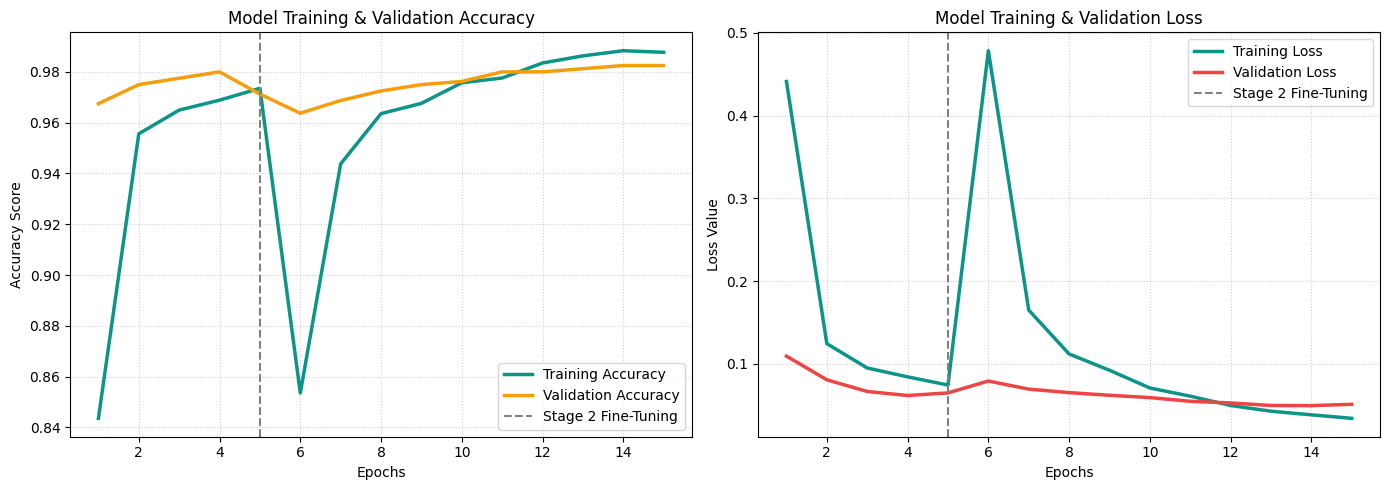

In [ ]:
import matplotlib.pyplot as plt

# Combine history from Stage 1 and Stage 2 fine-tuning
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Plot Accuracy Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='#0d9488', linewidth=2.5)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='#f59e0b', linewidth=2.5)
plt.axvline(x=5, color='gray', linestyle='--', label='Stage 2 Fine-Tuning')
plt.title('Model Training & Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy Score')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# Plot Loss Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='#0d9488', linewidth=2.5)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='#ef4444', linewidth=2.5)
plt.axvline(x=5, color='gray', linestyle='--', label='Stage 2 Fine-Tuning')
plt.title('Model Training & Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Found 802 files belonging to 6 classes.
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step


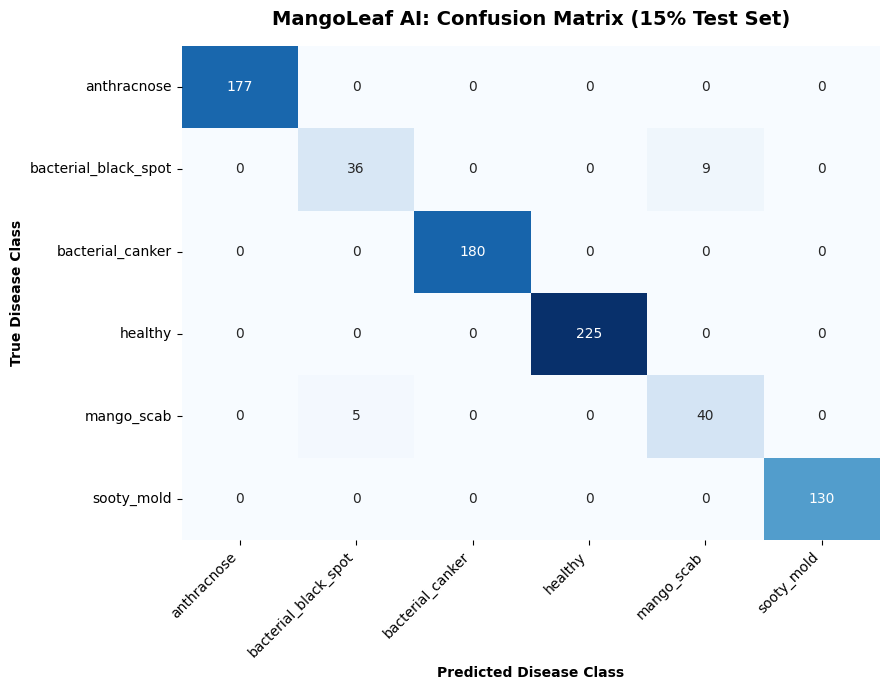


📋 Classification Report (Precision, Recall, F1-Score):
                      precision    recall  f1-score   support

         anthracnose       1.00      1.00      1.00       177
bacterial_black_spot       0.88      0.80      0.84        45
    bacterial_canker       1.00      1.00      1.00       180
             healthy       1.00      1.00      1.00       225
          mango_scab       0.82      0.89      0.85        45
          sooty_mold       1.00      1.00      1.00       130

            accuracy                           0.98       802
           macro avg       0.95      0.95      0.95       802
        weighted avg       0.98      0.98      0.98       802



In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

# Load test dataset with shuffle=False so predictions match true labels 1-to-1
test_gen_unshuffled = tf.keras.utils.image_dataset_from_directory(
'dataset/test',
image_size=(224, 224),
batch_size=32,
shuffle=False
)

# Predict on un-shuffled test set
y_true = np.concatenate([y.numpy() for x, y in test_gen_unshuffled], axis=0)
y_pred_probs = model.predict(test_gen_unshuffled)
y_pred = np.argmax(y_pred_probs, axis=1)

class_names = test_gen_unshuffled.class_names

# Compute Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.title('MangoLeaf AI: Confusion Matrix (15% Test Set)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Disease Class', fontweight='bold')
plt.ylabel('True Disease Class', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Print Precision, Recall, F1-Score Table
print("\n📋 Classification Report (Precision, Recall, F1-Score):")
print(classification_report(y_true, y_pred, target_names=class_names))

### Step 7: Export SavedModel & Convert to TensorFlow.js Graph Model

In [ ]:
model.export('mangoleaf_saved_model')

!pip install tensorflowjs
!tensorflowjs_converter --input_format=tf_saved_model mangoleaf_saved_model public/model

print('🎉 Model Conversion Complete! Download files in public/model and paste into off-on-sync/public/model/')

Saved artifact at 'mangoleaf_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  134251878767824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878769936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878769552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878770128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878770512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878770704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878770896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878771280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878768400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878768784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134251878

2026-07-24 21:53:21.813954: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1784930001.836597   17451 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1784930001.844096   17451 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1784930001.862528   17451 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1784930001.862577   17451 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1784930001.862582   17451 computation_placer.cc:177] computation placer alr

In [ ]:
import shutil
shutil.make_archive('/content/drive/MyDrive/mango_dataset_split_70_15_15', 'zip', 'dataset')
print("✅ Dataset zipped and saved to Google Drive as mango_dataset_split_70_15_15.zip!")

✅ Dataset zipped and saved to Google Drive as mango_dataset_split_70_15_15.zip!
